In [2]:
import sys
import os
import numpy as np
import scipy as sp
import pandas as pd
from matplotlib import pyplot as plt

from sklearn.cross_decomposition import PLSCanonical


sys.path.append(os.path.join(os.getcwd(), '../'))
from utils_fly import read_utils

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils
from utils import train_utils

In [3]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)

<module 'utils.train_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/organisms/fly-2023-schaffer/src/manifold/../../../../utils/train_utils.py'>

In [4]:
dims = 3

# read_ids = list(range(0, 12+1))
read_ids = [0,   # paper
			2,
			3,
			4,
			5,
			6,
			8,
			9]   # good
# read_ids = [0, 2, 3, 8, 9]
# read_ids = [6]
plot_id = 0

In [5]:
# read

path = os.path.join(read_utils.get_data_path(), 'brain')
(file_ids, filenames,
 traces,
 states, markers) = read_utils.get_data(path, read_ids)

# # clear nan values
# for i in range(len(file_ids)):
# 	mask = markers[i].notna().all(axis=1)
#
# 	traces[i] = traces[i][mask]
# 	markers[i] = markers[i][mask]
# 	states[i] = states[i][mask]
#
# 	#filenames[i] = filenames[i][mask]

# naive ID unknown neurons
for i in range(len(file_ids)):
	traces[i].columns = pd.Index([
		f'{file_ids[i]:02d}_{n_id:03d}' if empty else label for n_id, (label, empty) in enumerate(zip(traces[i].columns, traces[i].columns == ''))
	])

In [6]:
# prep

def highpass_butter(x, fs, cutoff_hz, order=4, axis=0):
    return sp.signal.sosfiltfilt(sp.signal.butter(order, cutoff_hz, btype='highpass', fs=fs, output='sos'), x, axis=axis)

sampling_rates = [read_utils.get_sampling_rate(os.path.join(path, filenames[file_ids.index(file_id)])) for file_id in file_ids]

traces = [pd.DataFrame(highpass_butter(trace.values, sr, 1 / 100), columns=trace.columns) for trace, sr in zip(traces, sampling_rates)]

markers_zs = [
	pd.DataFrame(
		data=(marker.values - marker.values.mean(axis=0)) / np.where((marker_std := np.std(marker.values, axis=0)) == 0.0, 1.0, marker_std),
		columns=marker.columns)
	for marker in markers
]
markers_grad = [pd.DataFrame(np.gradient(marker.values, axis=0), columns=marker.columns) for marker in markers]
markers_grad_zs = [
	pd.DataFrame(
		data=(marker_grad.values - marker_grad.values.mean(axis=0)) / np.where((marker_grad_std := np.std(marker_grad.values, axis=0)) == 0.0, 1.0, marker_grad_std),
		columns=marker_grad.columns)
	for marker_grad in markers_grad
]

In [7]:
selection_bhl = ['walk', 'still', 'front-groom', 'back-groom', 'abdomen-move', 'background']

plot_idx = file_ids.index(plot_id)

# discrete_states = [ds[selection_bhl] for ds in discrete_states]

In [9]:
(modes_manifold, modes_manifold_b,
 recos_manifold, recos_manifold_b,
 loads_cca_man, loads_cca_man_b,
 vars_expl_mans) = train_utils.get_manifolds_plsc(traces,
												  [s[selection_bhl] for s in states],
												  n_ls=dims)

In [10]:
save = False

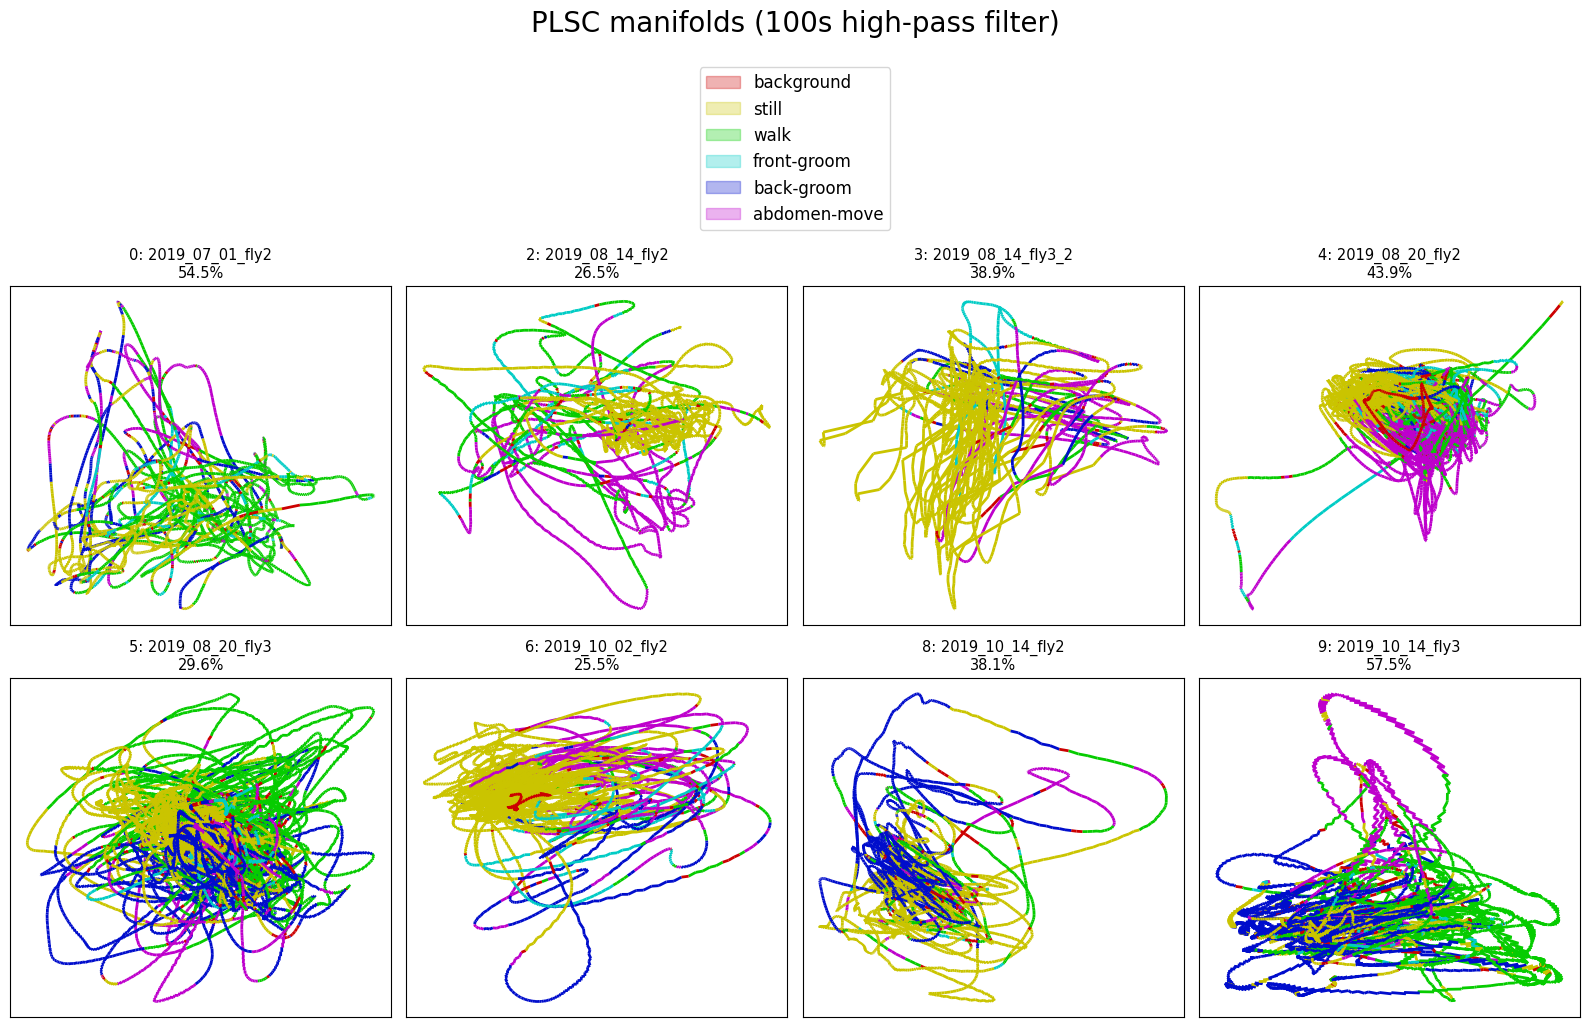

39.3%


In [11]:
plot_utils.plot_manifolds([f'{str(file_id)}: {filenames[file_ids.index(file_id)]}' for file_id in file_ids],
						  modes_manifold, states,
						  [vx[:2] for vx in vars_expl_mans], None,
						  title='PLSC manifolds (100s high-pass filter)', top_space=2.5,
						  save_path=f'../../out/plots/manifolds/{dims}-dim-PLSC' if save else None)

In [12]:
# plot_utils.plot_manifolds_3d([f'{str(file_id)}: {filenames[file_ids.index(file_id)]}' for file_id in file_ids],
# 							 modes_manifold, states,
# 							 [vx[:3] for vx in vars_expl_mans], None,
# 							 title='PSLC manifolds (100s high-pass filter)', top_space=3,
# 							 save_path=f'../../out/plots/manifolds/{dims}-dim-PLSC_3d' if save else None)